<a href="https://colab.research.google.com/github/Vasco-07/ds-projects/blob/main/8-Exp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
!pip install vaderSentiment

In [15]:

from bs4 import BeautifulSoup
import pandas as pd

# Read the saved HTML file
with open("reviews.html", "r", encoding="utf-8") as file:
    html_content = file.read()

soup = BeautifulSoup(html_content, "html.parser")

# Find review elements
review_blocks = soup.select(".review")

records = []

for block in review_blocks:
    review_element = block.select_one(".review-text")
    rating_element = block.select_one(".rating")
    title_element = block.select_one(".review-title")

    review_text = (
        review_element.get_text(" ", strip=True)
        if review_element else ""
    )

    rating_text = (
        rating_element.get_text(" ", strip=True)
        if rating_element else ""
    )

    title = (
        title_element.get_text(" ", strip=True)
        if title_element else ""
    )

    if review_text:
        records.append({
            "title": title,
            "review": review_text,
            "rating": rating_text
        })

df = pd.DataFrame(records)

# Save reviews to CSV
df.to_csv("product_reviews.csv", index=False, encoding="utf-8-sig")

print(df.head())
print("Total reviews extracted:", len(df))
print("Saved to product_reviews.csv")


                 title                                             review  \
0   Fantastic product!  I absolutely love this product! It has changed...   
1  Not worth the money  Terrible quality. It broke after only two days...   
2              Average  It works as described, but nothing special. Th...   
3    Excellent quality  Great value for the price. The build quality f...   
4           Pretty bad  Slow, laggy, and difficult to set up. I would ...   

    rating  
0  5 stars  
1   1 star  
2  3 stars  
3  5 stars  
4  2 stars  
Total reviews extracted: 5
Saved to product_reviews.csv


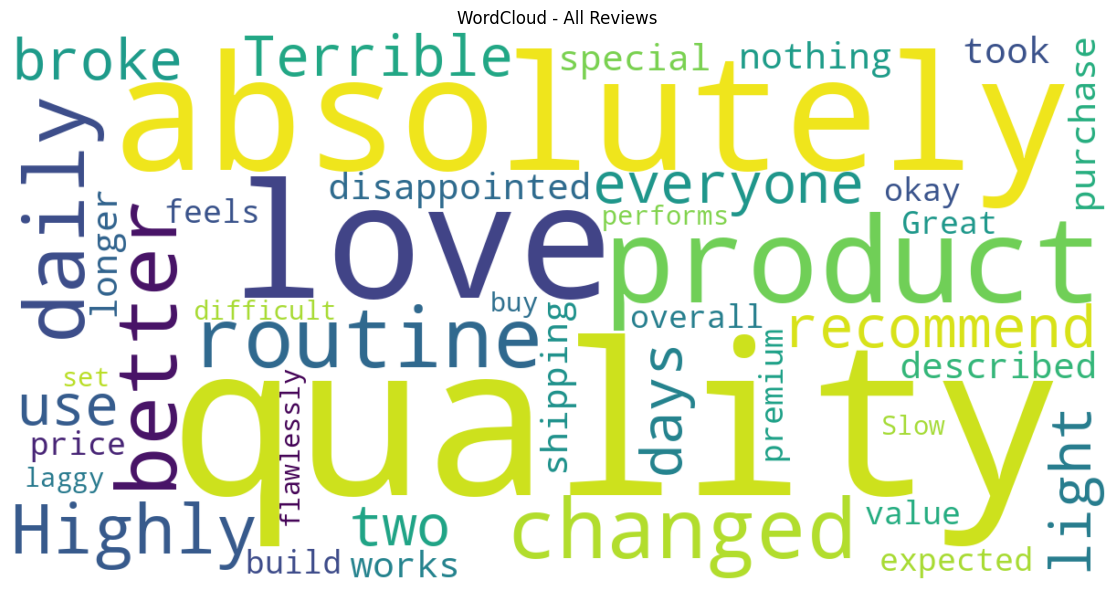

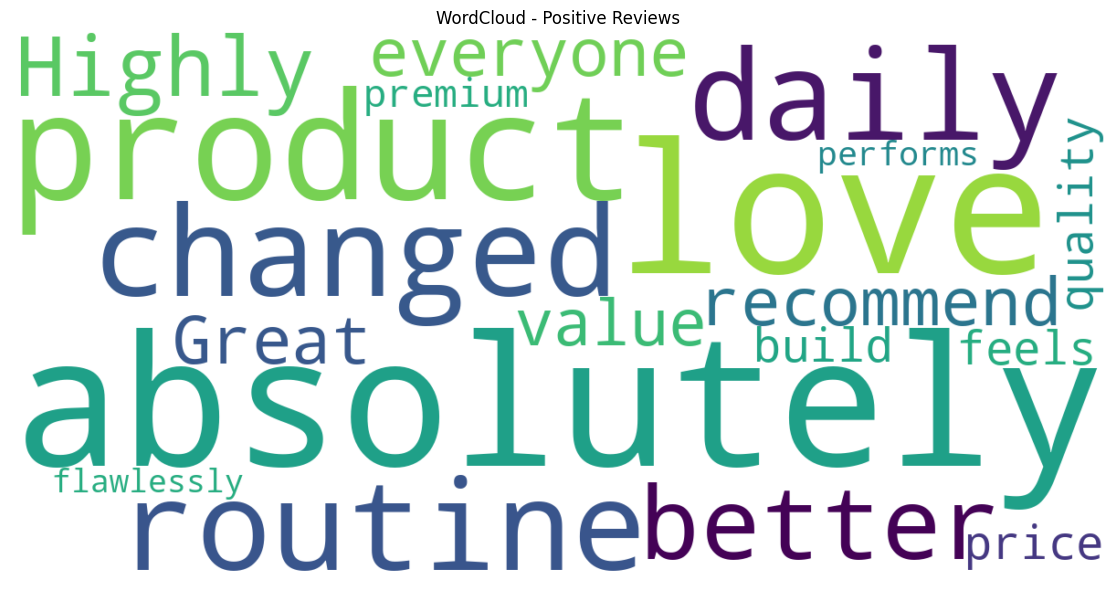

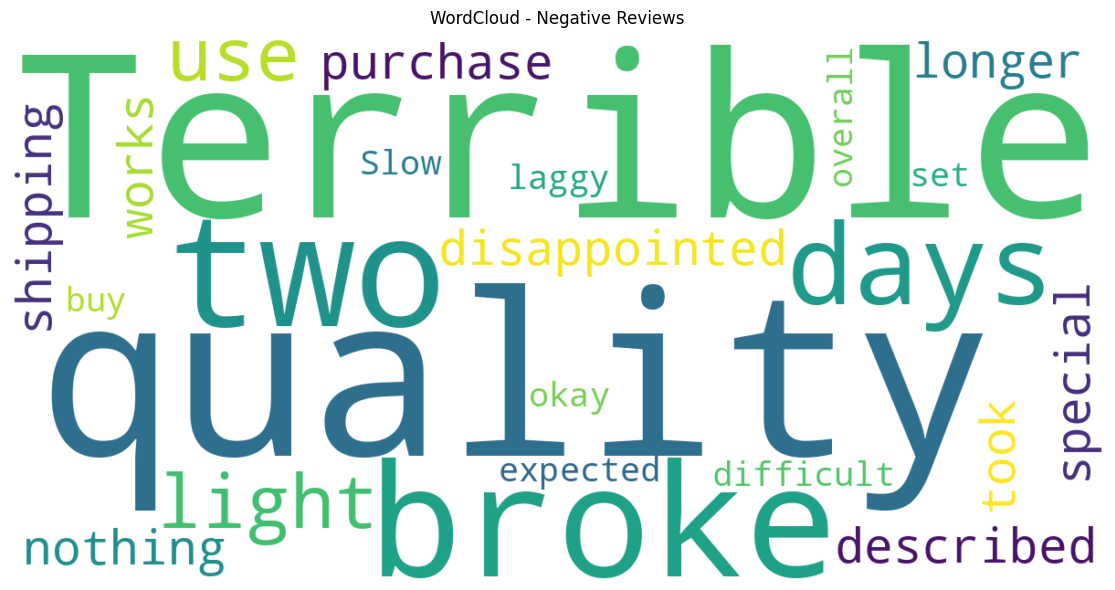

sentiment
Negative    3
Positive    2
Name: count, dtype: int64
WordCloud images saved successfully.


In [16]:

import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Load reviews
df = pd.read_csv("product_reviews.csv")
df["review"] = df["review"].fillna("").astype(str)

# Initialize sentiment analyzer
analyzer = SentimentIntensityAnalyzer()

def classify_sentiment(text):
    score = analyzer.polarity_scores(text)["compound"]

    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"

df["sentiment"] = df["review"].apply(classify_sentiment)

# Generate WordCloud
def generate_wordcloud(text, title, filename):
    if not text.strip():
        print(f"No text available for: {title}")
        return

    cloud = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        max_words=150,
        collocations=False
    ).generate(text)

    plt.figure(figsize=(12, 6))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

# WordCloud for all reviews
all_text = " ".join(df["review"])
generate_wordcloud(
    all_text, "WordCloud - All Reviews", "wordcloud_all.png"
)

# WordCloud for positive reviews
positive_text = " ".join(
    df.loc[df["sentiment"] == "Positive", "review"]
)
generate_wordcloud(
    positive_text, "WordCloud - Positive Reviews",
    "wordcloud_positive.png"
)

# WordCloud for negative reviews
negative_text = " ".join(
    df.loc[df["sentiment"] == "Negative", "review"]
)
generate_wordcloud(
    negative_text, "WordCloud - Negative Reviews",
    "wordcloud_negative.png"
)

# Save analyzed data
df.to_csv("product_reviews_analyzed.csv", index=False)

print(df["sentiment"].value_counts())
print("WordCloud images saved successfully.")


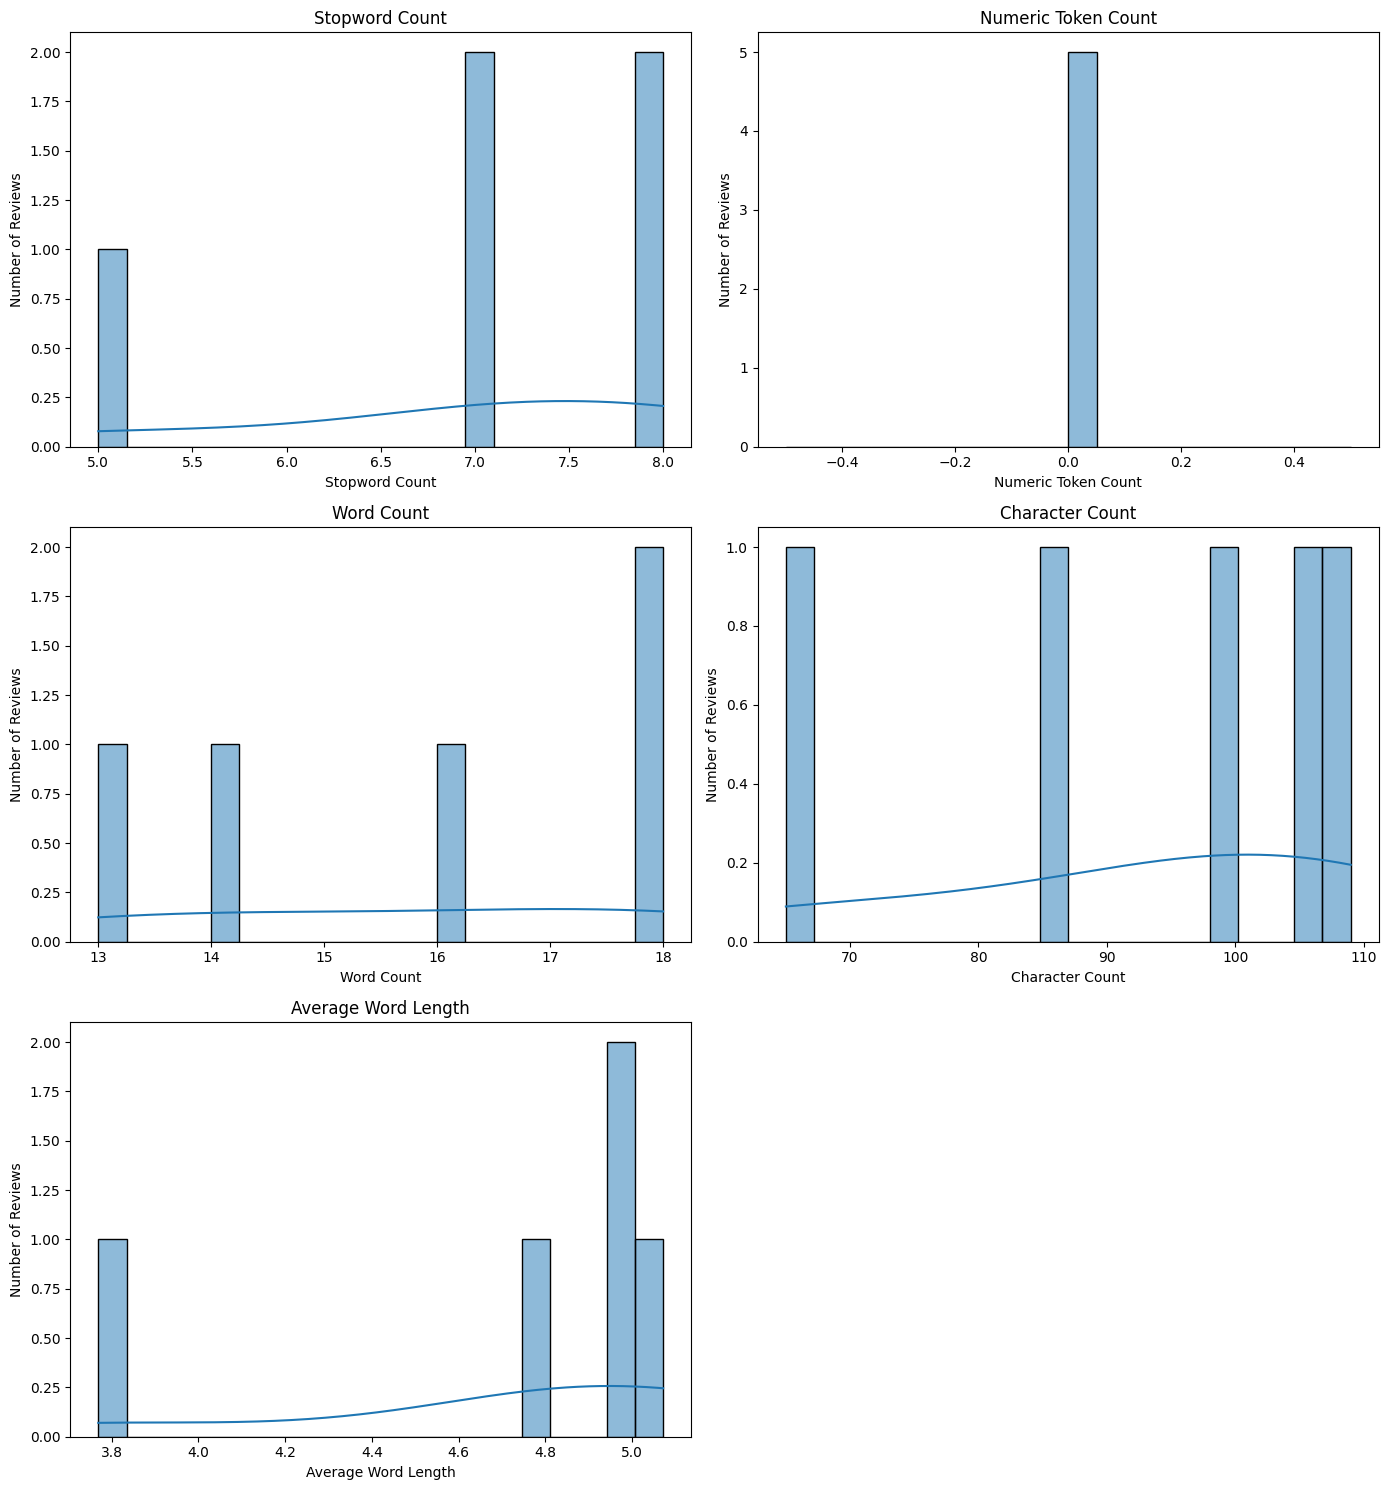

Top 10 stopwords:
[('it', 5), ('the', 4), ('this', 3), ('i', 2), ('for', 2), ('to', 2), ('but', 2), ('and', 2), ('has', 1), ('my', 1)]

Descriptive statistics:
       stopword_count  numeric_count  word_count  character_count  \
count        5.000000            5.0    5.000000         5.000000   
mean         7.000000            0.0   15.800000        92.800000   
std          1.224745            0.0    2.280351        17.908099   
min          5.000000            0.0   13.000000        65.000000   
25%          7.000000            0.0   14.000000        86.000000   
50%          7.000000            0.0   16.000000        98.000000   
75%          8.000000            0.0   18.000000       106.000000   
max          8.000000            0.0   18.000000       109.000000   

       average_word_length  
count             5.000000  
mean              4.712576  
std               0.538354  
min               3.769231  
25%               4.777778  
50%               4.944444  
75%            

In [17]:

import re
import pandas as pd
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from collections import Counter

# Download stopwords
nltk.download("stopwords", quiet=True)

# Load reviews
df = pd.read_csv("product_reviews.csv")
df["review"] = df["review"].fillna("").astype(str)

stop_words = set(stopwords.words("english"))

# Analyze each review
def analyze_review(text):
    tokens = re.findall(r"\b[\w']+\b", text.lower())
    words = re.findall(r"\b[A-Za-z]+\b", text)
    numeric_tokens = re.findall(r"\b\d+(?:\.\d+)?\b", text)

    stopword_tokens = [
        token for token in tokens if token in stop_words
    ]

    return pd.Series({
        "word_count": len(tokens),
        "character_count": len(text),
        "numeric_count": len(numeric_tokens),
        "stopword_count": len(stopword_tokens),
        "average_word_length": (
            sum(len(word) for word in words) / len(words)
            if words else 0
        )
    })

statistics = df["review"].apply(analyze_review)
df = pd.concat([df, statistics], axis=1)

# Save calculated statistics
df.to_csv("review_statistics.csv", index=False)

# Plot distributions
columns = [
    ("stopword_count", "Stopword Count"),
    ("numeric_count", "Numeric Token Count"),
    ("word_count", "Word Count"),
    ("character_count", "Character Count"),
    ("average_word_length", "Average Word Length")
]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for i, (column, title) in enumerate(columns):
    sns.histplot(
        data=df, x=column, kde=True,
        ax=axes[i], bins=20
    )
    axes[i].set_title(title)
    axes[i].set_xlabel(title)
    axes[i].set_ylabel("Number of Reviews")

axes[-1].axis("off")
plt.tight_layout()
plt.savefig("review_statistics_distributions.png", dpi=300)
plt.show()

# Find the most common stopwords
all_tokens = re.findall(
    r"\b[\w']+\b",
    " ".join(df["review"]).lower()
)

stopword_frequency = Counter(
    token for token in all_tokens if token in stop_words
)

print("Top 10 stopwords:")
print(stopword_frequency.most_common(10))

# Display descriptive statistics
print("\nDescriptive statistics:")
print(df[[
    "stopword_count",
    "numeric_count",
    "word_count",
    "character_count",
    "average_word_length"
]].describe())
